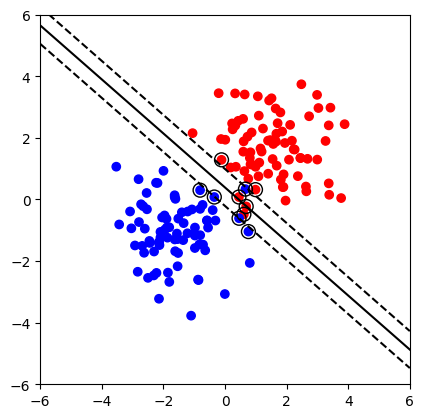

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
np.random.seed(0)
# X1 = np.random.randn(50, 2) + np.array([2, 2])
# X2 = np.random.randn(50, 2) + np.array([-2,-2])
# X = np.vstack((X1, X2)) # feature
# y = np.array([1]*50 + [-1]*50) # label
X1 = np.random.randn(80, 2) + np.array([1.5, 1.5])
X2 = np.random.randn(80, 2) + np.array([-1.5,-1.0])
X = np.vstack((X1, X2))
y = np.array([1]*80 + [-1]*80)

model = SVC(kernel='linear', C=1.0)
model.fit(X, y)
fig, ax = plt.subplots()
ax.scatter(X[:, 0], X[:, 1], c=y, cmap='bwr')
w = model.coef_[0]
b = model.intercept_[0]
x_vals = np.linspace(-6, 6, 100) # line: w0*x + w1*y + b = 0 -> y = -(w0/w1)x - b/w1
y_vals = -(w[0]/w[1]) * x_vals - b / w[1]
ax.plot(x_vals, y_vals, 'k-') # decision boundary

margin = 1 / np.linalg.norm(w)
y_margin1 = y_vals + margin
y_margin2 = y_vals - margin
ax.plot(x_vals, y_margin1, 'k--')
ax.plot(x_vals, y_margin2, 'k--')
ax.scatter(model.support_vectors_[:,0], # support vectors
model.support_vectors_[:,1],
s=100, facecolors='none', edgecolors='k')
ax.set_xlim(-6, 6)
ax.set_ylim(-6, 6)
ax.set_aspect('equal')
plt.show()

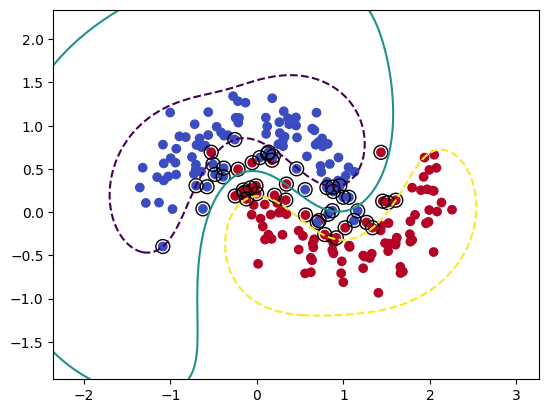

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.svm import SVC
X, y = make_moons(n_samples=200, noise=0.2, random_state=0)
model = SVC(kernel='rbf', C=1.0, gamma=1.0)
model.fit(X, y)
x_min, x_max = X[:,0].min() - 1, X[:,0].max() + 1 # generate grid
y_min, y_max = X[:,1].min() - 1, X[:,1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), # x & y : 300x300
np.linspace(y_min, y_max, 300))

Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]) # 90000x1
Z = Z.reshape(xx.shape) # 300x300
plt.figure()
# decision boundary & margin
plt.contour(xx, yy, Z, levels=[-1, 0, 1], linestyles=['--','-','--'])
plt.scatter(X[:,0], X[:,1], c=y, cmap='coolwarm') # data
plt.scatter(model.support_vectors_[:,0], # support vectors
model.support_vectors_[:,1],
s=100, facecolors='none', edgecolors='k')
plt.gca().set_aspect('equal')
plt.show()

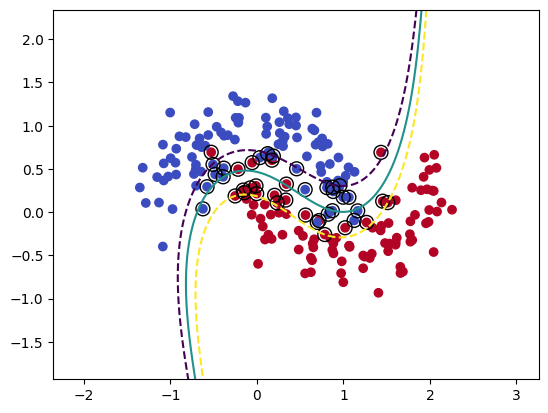

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.svm import SVC
X, y = make_moons(n_samples=200, noise=0.2, random_state=0)
model = SVC(kernel='poly', degree=3, C=1.0, coef0=1)
model.fit(X, y)
x_min, x_max = X[:,0].min() - 1, X[:,0].max() + 1 # generate grid
y_min, y_max = X[:,1].min() - 1, X[:,1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), # x & y : 300x300
np.linspace(y_min, y_max, 300))

Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]) # 90000x1
Z = Z.reshape(xx.shape) # 300x300
plt.figure()
# decision boundary & margin
plt.contour(xx, yy, Z, levels=[-1, 0, 1], linestyles=['--','-','--'])
plt.scatter(X[:,0], X[:,1], c=y, cmap='coolwarm') # data
plt.scatter(model.support_vectors_[:,0], # support vectors
model.support_vectors_[:,1],
s=100, facecolors='none', edgecolors='k')
plt.gca().set_aspect('equal')
plt.show()

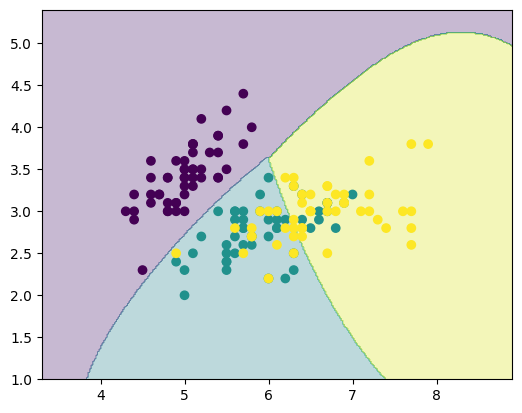

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm, datasets
iris = datasets.load_iris()
X = iris.data[:, :2] # only 2 features
y = iris.target # 3 classes, 1-1 method, 3 classifiers
model = svm.SVC(kernel='rbf', C=1.5)
model.fit(X, y)
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
np.linspace(y_min, y_max, 300))
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)
plt.figure()
plt.contourf(xx, yy, Z, alpha=0.3) # boundary
plt.scatter(X[:,0], X[:,1], c=y) # data
plt.gca().set_aspect('equal')
plt.show()